[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/diogoflim/iap/blob/main/04_Leonardo.ipynb)

# UNIVERSIDADE FEDERAL FLUMINENSE

**Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

---
# AULA 04 — CLASSIFICAÇÃO E REDES PROFUNDAS
---

Até agora a rede previa um **número** (regressão). Muitos problemas práticos, porém, pedem uma **categoria**: a peça é defeituosa ou não? O cliente vai cancelar ou não? Que dígito está escrito nesta imagem?

**O que você vai aprender**

- usar uma rede para **classificar** (duas classes e várias classes);
- medir o desempenho com a **acurácia**;
- construir redes **profundas** (com várias camadas ocultas);
- treinar com **lotes** de dados usando o `DataLoader`;
- reconhecer dígitos manuscritos no conjunto **MNIST**.

## 0. Importando as bibliotecas

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

---
# PARTE 1 — Classificação com duas classes
---

## 1. Dados

O scikit-learn tem um gerador de dados clássico, `make_moons`: pontos no plano divididos em duas "luas" entrelaçadas. Cada ponto tem **duas** características ($x_1$ e $x_2$) e pertence à classe **0** ou à classe **1**.

In [2]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=600, noise=0.25, random_state=42)

print("formato de X:", X.shape)       # 600 pontos, 2 características
print("primeiros rótulos:", y[:10])   # 0 ou 1

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)

formato de X: (600, 2)
primeiros rótulos: [0 1 1 0 0 0 0 1 0 1]


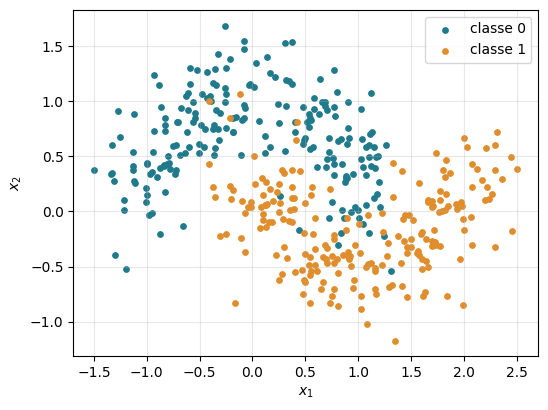

In [3]:
plt.figure(figsize=(6, 4.5))
plt.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], color=AZUL, s=15, label="classe 0")
plt.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], color=LARANJA, s=15, label="classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.legend(); plt.grid(alpha=0.3)
plt.show()


## 2. Tensores

- `X` já tem duas colunas, então **não** precisa de `reshape`;
- `y` vira uma coluna `(N, 1)` com valores `0.0` ou `1.0`.

In [4]:
X_treino = torch.tensor(X_tr, dtype=torch.float32)
Y_treino = torch.tensor(y_tr, dtype=torch.float32).reshape(-1, 1)
X_teste  = torch.tensor(X_te, dtype=torch.float32)
Y_teste  = torch.tensor(y_te, dtype=torch.float32).reshape(-1, 1)

print("X_treino:", X_treino.shape, "| Y_treino:", Y_treino.shape)

X_treino: torch.Size([420, 2]) | Y_treino: torch.Size([420, 1])


## 3. Modelo: uma rede profunda

Uma rede **profunda** é simplesmente uma rede com **mais de uma camada oculta**. Em código, basta empilhar mais pares `nn.Linear` + `nn.ReLU`:

- a entrada tem **2** números ($x_1$, $x_2$), então a primeira camada é `nn.Linear(2, ...)`;
- a saída é **1** número, que indica a classe.

In [5]:
rede = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),     # 1ª camada oculta: 16 neurônios
    nn.Linear(16, 16), nn.ReLU(),    # 2ª camada oculta: 16 neurônios
    nn.Linear(16, 1),                # saída: 1 número
)
print(rede)

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)


## 4. Perda e otimizador

Como transformar a saída da rede (um número qualquer, positivo ou negativo) em uma classe?

1. A função **sigmoide** "espreme" qualquer número para o intervalo entre 0 e 1. Interpretamos o resultado como a **probabilidade** de o ponto ser da classe 1.
2. Se a probabilidade passar de 0,5, dizemos que é classe 1; senão, classe 0.

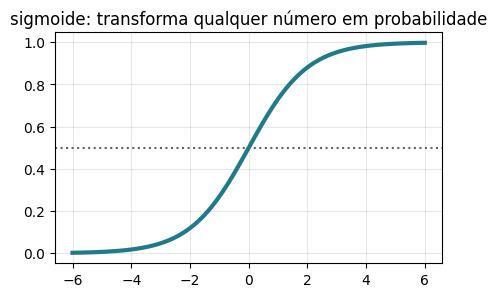

In [6]:
z = torch.linspace(-6, 6, 100)

plt.figure(figsize=(5, 3))
plt.plot(z, torch.sigmoid(z), color=AZUL, linewidth=3)
plt.axhline(0.5, color=CINZA, linestyle=":")
plt.title("sigmoide: transforma qualquer número em probabilidade"); plt.grid(alpha=0.3)
plt.show()

Para treinar, usamos a perda **`nn.BCEWithLogitsLoss`** (entropia cruzada binária). Ela aplica a sigmoide por dentro e mede o quão longe a probabilidade prevista está do rótulo correto. Por isso **não** colocamos a sigmoide dentro da rede.

| Tarefa | Saída da rede | Perda |
|---|---|---|
| regressão (prever um número) | 1 número | `nn.MSELoss()` |
| classificação com 2 classes | 1 número | `nn.BCEWithLogitsLoss()` |

In [7]:
perda_fn = nn.BCEWithLogitsLoss()
otimizador = torch.optim.Adam(rede.parameters(), lr=0.01)

## 5. Laço de treino

Exatamente o mesmo de sempre.

In [8]:
for epoca in range(1000):
    saida = rede(X_treino)
    perda = perda_fn(saida, Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

    if epoca % 200 == 0:
        print(f"época {epoca:4d} | perda = {perda.item():.4f}")

época    0 | perda = 0.6950
época  200 | perda = 0.1384
época  400 | perda = 0.1269


época  600 | perda = 0.1195
época  800 | perda = 0.1105


## 6. Avaliação: a acurácia

Em classificação, a medida mais intuitiva é a **acurácia**: a fração de exemplos classificados corretamente.

In [9]:
with torch.no_grad():
    probabilidade = torch.sigmoid(rede(X_teste))     # número entre 0 e 1
    classe_prevista = (probabilidade > 0.5).float()   # 1.0 se passar de 0,5; senão 0.0

acertos = (classe_prevista == Y_teste).float()      # 1 onde acertou, 0 onde errou
print("acurácia no teste:", acertos.mean().item())

acurácia no teste: 0.9111111164093018


### Vendo o que a rede aprendeu

A função abaixo pinta cada região do plano com a classe que a rede prevê ali. **Não é preciso entender o código desta função**: ela só desenha o gráfico.

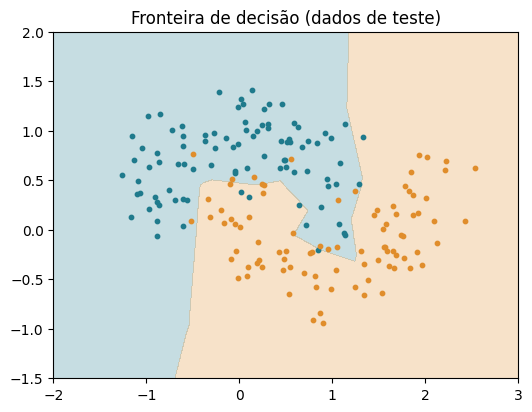

In [10]:
def desenha_fronteira(modelo, X, y, titulo=""):
    # cria uma grade de pontos cobrindo o plano e pede a previsão da rede em cada um
    g1, g2 = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grade = torch.tensor(np.c_[g1.ravel(), g2.ravel()], dtype=torch.float32)
    with torch.no_grad():
        prob = torch.sigmoid(modelo(grade)).reshape(g1.shape)
    plt.contourf(g1, g2, prob, levels=[0, 0.5, 1], colors=[AZUL, LARANJA], alpha=0.25)
    plt.scatter(X[y == 0, 0], X[y == 0, 1], color=AZUL, s=10)
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color=LARANJA, s=10)
    plt.title(titulo)


plt.figure(figsize=(6, 4.5))
desenha_fronteira(rede, X_te, y_te, "Fronteira de decisão (dados de teste)")
plt.show()

## 7. Rasa ou profunda?

Vamos comparar três redes: **sem** camada oculta, com **uma** e com **três**. Para isso, uma pequena função que monta a rede com o número de camadas ocultas que pedirmos:

In [11]:
def criar_rede(n_camadas_ocultas, neuronios=16):
    camadas = []
    entrada = 2
    for i in range(n_camadas_ocultas):
        camadas.append(nn.Linear(entrada, neuronios))
        camadas.append(nn.ReLU())
        entrada = neuronios
    camadas.append(nn.Linear(entrada, 1))      # camada de saída
    return nn.Sequential(*camadas)             # o * "desempacota" a lista



print(criar_rede(0))
print('-------------------------------')
print(criar_rede(1))
print('-------------------------------')
print(criar_rede(3))

Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
)
-------------------------------
Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
-------------------------------
Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=1, bias=True)
)


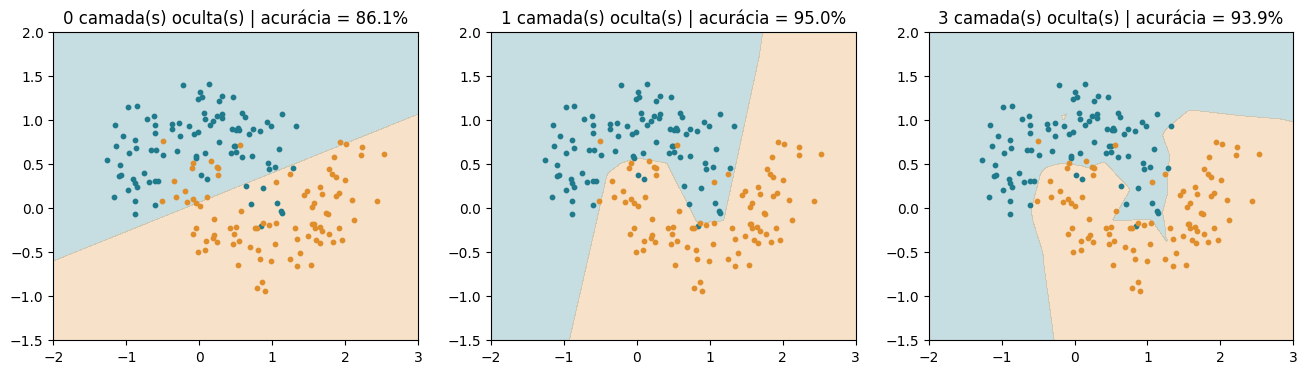

In [12]:
def treinar_classificador(modelo, epocas=1000):
    perda_fn = nn.BCEWithLogitsLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=0.01)
    for epoca in range(epocas):
        perda = perda_fn(modelo(X_treino), Y_treino)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()


def acuracia(modelo, X, Y):
    with torch.no_grad():
        classe = (torch.sigmoid(modelo(X)) > 0.5).float()
    return (classe == Y).float().mean().item()


plt.figure(figsize=(16, 4))
for i, n in enumerate([0, 1, 3]):
    torch.manual_seed(42)
    modelo = criar_rede(n)
    treinar_classificador(modelo)
    plt.subplot(1, 3, i + 1)
    desenha_fronteira(modelo, X_te, y_te, f"{n} camada(s) oculta(s) | acurácia = {acuracia(modelo, X_teste, Y_teste):.1%}")
plt.show()

- **Sem camada oculta**, a rede só consegue traçar uma **linha reta**: é o limite de um modelo linear.
- Com camadas ocultas, a fronteira se **dobra** e acompanha o formato das luas.
- Mais camadas **nem sempre** significam mais acurácia. Modelos muito complexos para problemas simples podem gerar overfitting.

Agora vamos a um problema de verdade.

---
# PARTE 2 — Reconhecendo dígitos: o MNIST
---

O **MNIST** é o conjunto de dados mais famoso do aprendizado profundo: 70 mil imagens de dígitos escritos à mão (0 a 9), cada uma com $28 \times 28$ pixels.

## 1. Dados

A biblioteca `torchvision` (irmã do PyTorch) baixa o MNIST automaticamente. O argumento `transform=transforms.ToTensor()` converte cada imagem em um tensor com valores entre 0 e 1.

In [13]:
from torchvision import datasets, transforms

mnist_treino = datasets.MNIST(root="dados", train=True,  download=True, transform=transforms.ToTensor())
mnist_teste  = datasets.MNIST(root="dados", train=False, download=True, transform=transforms.ToTensor())

print("imagens de treino:", len(mnist_treino))
print("imagens de teste :", len(mnist_teste))

imagens de treino: 60000
imagens de teste : 10000


Cada elemento do conjunto é um par **(imagem, rótulo)**:

In [14]:
imagem, rotulo = mnist_treino[0]
print("formato da imagem:", imagem.shape)    # 1 canal (tons de cinza), 28 x 28 pixels
print("rótulo:", rotulo)

formato da imagem: torch.Size([1, 28, 28])
rótulo: 5


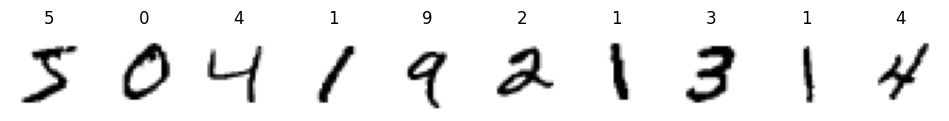

In [15]:
plt.figure(figsize=(12, 2.5))
for i in range(10):
    imagem, rotulo = mnist_treino[i]
    plt.subplot(1, 10, i + 1)
    plt.imshow(imagem[0], cmap="gray_r")
    plt.title(rotulo); plt.axis("off")
plt.show()

## 2. Lotes de dados: o `DataLoader`

São 60 mil imagens. Em vez de passar todas pela rede de uma vez, dividimos os dados em **lotes** (*batches*) pequenos, por exemplo de 64 imagens. A cada lote, a rede dá um passo de correção. Isso é mais rápido e usa menos memória.

O `DataLoader` faz essa divisão para nós (e embaralha os dados a cada época com `shuffle=True`):

In [16]:
from torch.utils.data import DataLoader

carregador_treino = DataLoader(mnist_treino, batch_size=64, shuffle=True)
carregador_teste  = DataLoader(mnist_teste,  batch_size=1000)

imagens, rotulos = next(iter(carregador_treino))     # pega o primeiro lote, só para ver
print("um lote de imagens:", imagens.shape)          # 64 imagens de 1 x 28 x 28
print("um lote de rótulos:", rotulos.shape)
print("número de lotes por época:", len(carregador_treino))

um lote de imagens: torch.Size([64, 1, 28, 28])
um lote de rótulos: torch.Size([64])
número de lotes por época: 938


## 3. Modelo

A rede recebe números em fila, não imagens. Por isso, a primeira peça é `nn.Flatten()`, que "achata" cada imagem $28 \times 28$ em uma fila de $784$ números.

A saída tem **10** números, um para cada dígito. O dígito com o **maior** número é a previsão da rede.

In [17]:
torch.manual_seed(42)
rede_mnist = nn.Sequential(
    nn.Flatten(),                      # 1 x 28 x 28  ->  784
    nn.Linear(784, 128), nn.ReLU(),    # 1ª camada oculta
    nn.Linear(128, 64), nn.ReLU(),     # 2ª camada oculta
    nn.Linear(64, 10),                 # 10 saídas: uma para cada dígito
)
print(rede_mnist)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=10, bias=True)
)


## 4. Perda e otimizador

Para **mais de duas classes**, a perda é a **`nn.CrossEntropyLoss`** (entropia cruzada). Ela recebe os 10 números da rede e o rótulo correto (um inteiro de 0 a 9).

| Tarefa | Saída da rede | Perda |
|---|---|---|
| regressão | 1 número | `nn.MSELoss()` |
| 2 classes | 1 número | `nn.BCEWithLogitsLoss()` |
| várias classes | 1 número por classe | `nn.CrossEntropyLoss()` |

In [18]:
perda_fn = nn.CrossEntropyLoss()
otimizador = torch.optim.Adam(rede_mnist.parameters(), lr=0.001)

## 5. Laço de treino com lotes

A única mudança no laço: agora há um **segundo `for`**, que percorre os lotes. Uma **época** é uma passada completa por todos os lotes.

> Esta célula leva cerca de 10 a 20 segundos.

In [19]:
for epoca in range(3):
    for imagens, rotulos in carregador_treino:      # percorre os lotes
        saida = rede_mnist(imagens)
        perda = perda_fn(saida, rotulos)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()

    print(f"época {epoca + 1} concluída | perda no último lote = {perda.item():.4f}")

época 1 concluída | perda no último lote = 0.0419


época 2 concluída | perda no último lote = 0.0266


época 3 concluída | perda no último lote = 0.0796


## 6. Avaliação

Percorremos os lotes do teste contando os acertos. O método `.argmax(dim=1)` devolve a posição do maior dos 10 números, ou seja, o dígito previsto.

In [20]:
acertos = 0
total = 0
with torch.no_grad():
    for imagens, rotulos in carregador_teste:
        saida = rede_mnist(imagens)
        previsto = saida.argmax(dim=1)
        acertos = acertos + (previsto == rotulos).sum().item()
        total = total + len(rotulos)

print(f"acurácia no teste: {acertos / total:.2%}  ({acertos} de {total} imagens)")

acurácia no teste: 97.00%  (9700 de 10000 imagens)


Com poucas linhas de código e menos de um minuto de treino, a rede acerta cerca de **97%** das imagens de teste.

### Vendo algumas previsões

Título em verde: acerto. Em vermelho: erro.

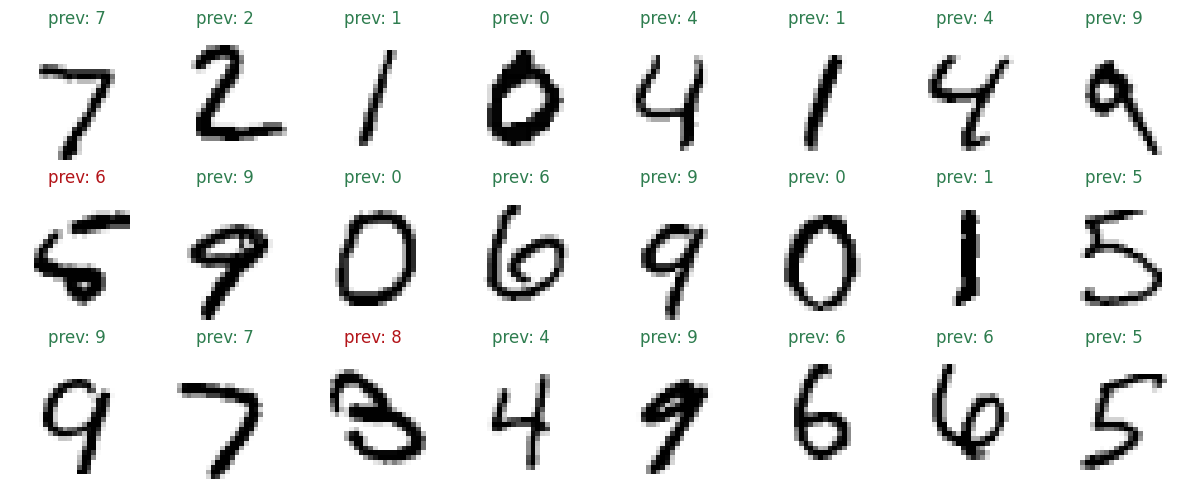

In [21]:
imagens, rotulos = next(iter(carregador_teste))
with torch.no_grad():
    previstos = rede_mnist(imagens).argmax(dim=1)

plt.figure(figsize=(12, 5))
for i in range(24):
    plt.subplot(3, 8, i + 1)
    plt.imshow(imagens[i][0], cmap="gray_r")
    cor = VERDE if previstos[i] == rotulos[i] else VERMELHO
    plt.title(f"prev: {previstos[i].item()}", color=cor); plt.axis("off")
plt.tight_layout(); plt.show()

E alguns **erros**, para entendermos onde a rede tem dificuldade:

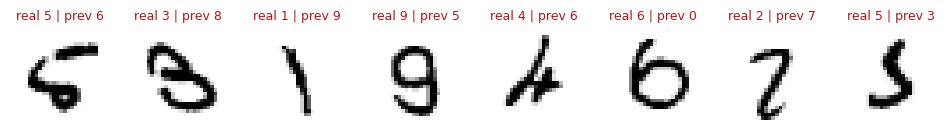

In [22]:
erros = (previstos != rotulos).nonzero().flatten()     # posições onde a rede errou

plt.figure(figsize=(12, 2.5))
for j, i in enumerate(erros[:8]):
    plt.subplot(1, 8, j + 1)
    plt.imshow(imagens[i][0], cmap="gray_r")
    plt.title(f"real {rotulos[i].item()} | prev {previstos[i].item()}", color=VERMELHO, fontsize=9)
    plt.axis("off")
plt.show()

Muitos erros são dígitos mal escritos, difíceis até para nós.

---
## Exercícios
---

**1.** Na Parte 1, troque `noise=0.25` por `noise=0.5` em `make_moons`. A acurácia cai? Por quê?

**2.** Na Parte 2, treine a rede por 5 épocas em vez de 3. A acurácia no teste melhora?

**3.** Ainda na Parte 2, remova a segunda camada oculta (deixe `nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)`). A acurácia muda muito?

**4.** Troque `datasets.MNIST` por `datasets.FashionMNIST` (imagens de roupas e calçados, mesmo formato). A rede acerta mais ou menos?

---
# RESOLUÇÃO DOS EXERCÍCIOS
---

**Aluno:** Leonardo

Nas células abaixo resolvo os quatro exercícios. Para que as comparações sejam justas, fixo as sementes aleatórias antes de criar cada rede e cada `DataLoader`. Assim, dois modelos comparados partem dos mesmos pesos iniciais e veem os lotes na mesma ordem, e a única diferença entre eles é a mudança pedida.

Um único treino pode dar um resultado "de sorte". Por isso, nos exercícios do MNIST repito cada experimento com **três sementes** e olho a média.

---
### Exercício 1 — Mais ruído nas luas

> Na Parte 1, troque `noise=0.25` por `noise=0.5` em `make_moons`. A acurácia cai? Por quê?

O parâmetro `noise` controla o desvio-padrão do ruído somado a cada ponto. Com mais ruído, os pontos se espalham mais em volta do formato das luas.

Para não sobrescrever as variáveis da aula, crio uma função que gera os dados já como tensores, e versões das funções de treino e de desenho que recebem os dados como argumento.

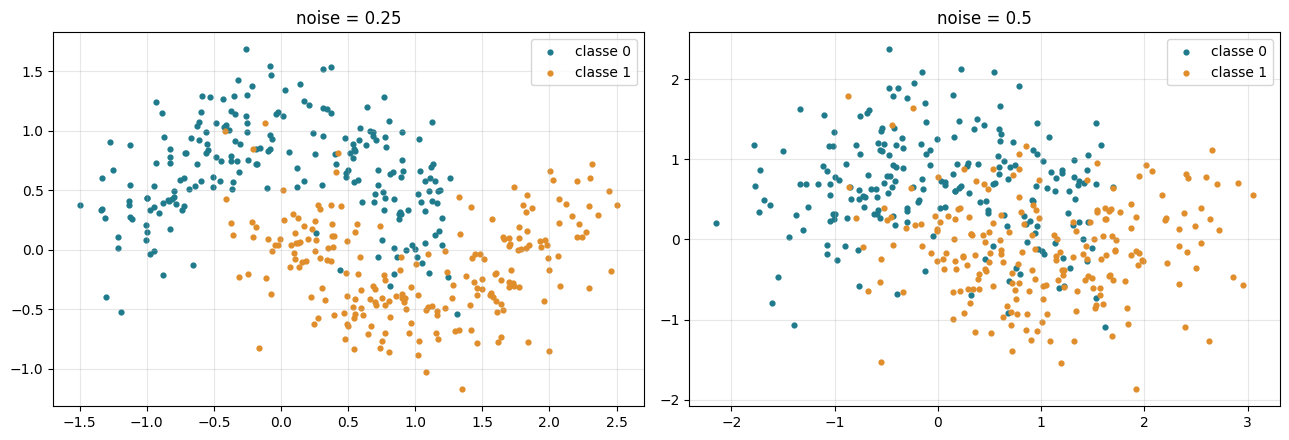

In [23]:
def gerar_luas(noise, n=600, semente=42):
    X, y = make_moons(n_samples=n, noise=noise, random_state=semente)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)
    tensores = (torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32).reshape(-1, 1),
                torch.tensor(X_te, dtype=torch.float32), torch.tensor(y_te, dtype=torch.float32).reshape(-1, 1))
    return (X_tr, X_te, y_tr, y_te), tensores


def treinar_luas(modelo, X, Y, epocas=1000):
    perda_fn = nn.BCEWithLogitsLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=0.01)
    for epoca in range(epocas):
        perda = perda_fn(modelo(X), Y)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()


def fronteira(eixo, modelo, X, y, titulo=""):
    # igual à desenha_fronteira da aula, mas com a grade ajustada aos dados (o ruído maior espalha os pontos)
    g1, g2 = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 250),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 250))
    grade = torch.tensor(np.c_[g1.ravel(), g2.ravel()], dtype=torch.float32)
    with torch.no_grad():
        prob = torch.sigmoid(modelo(grade)).reshape(g1.shape)
    eixo.contourf(g1, g2, prob, levels=[0, 0.5, 1], colors=[AZUL, LARANJA], alpha=0.25)
    eixo.scatter(X[y == 0, 0], X[y == 0, 1], color=AZUL, s=8)
    eixo.scatter(X[y == 1, 0], X[y == 1, 1], color=LARANJA, s=8)
    eixo.set_title(titulo, fontsize=10)


dados = {ruido: gerar_luas(ruido) for ruido in [0.25, 0.5]}

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
for eixo, (ruido, ((X_tr_, X_te_, y_tr_, y_te_), _)) in zip(eixos, dados.items()):
    eixo.scatter(X_tr_[y_tr_ == 0, 0], X_tr_[y_tr_ == 0, 1], color=AZUL, s=12, label="classe 0")
    eixo.scatter(X_tr_[y_tr_ == 1, 0], X_tr_[y_tr_ == 1, 1], color=LARANJA, s=12, label="classe 1")
    eixo.set_title(f"noise = {ruido}"); eixo.legend(); eixo.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Treino as mesmas três arquiteturas da Seção 7 (0, 1 e 3 camadas ocultas) nos dois conjuntos de dados e meço a acurácia no treino e no teste.

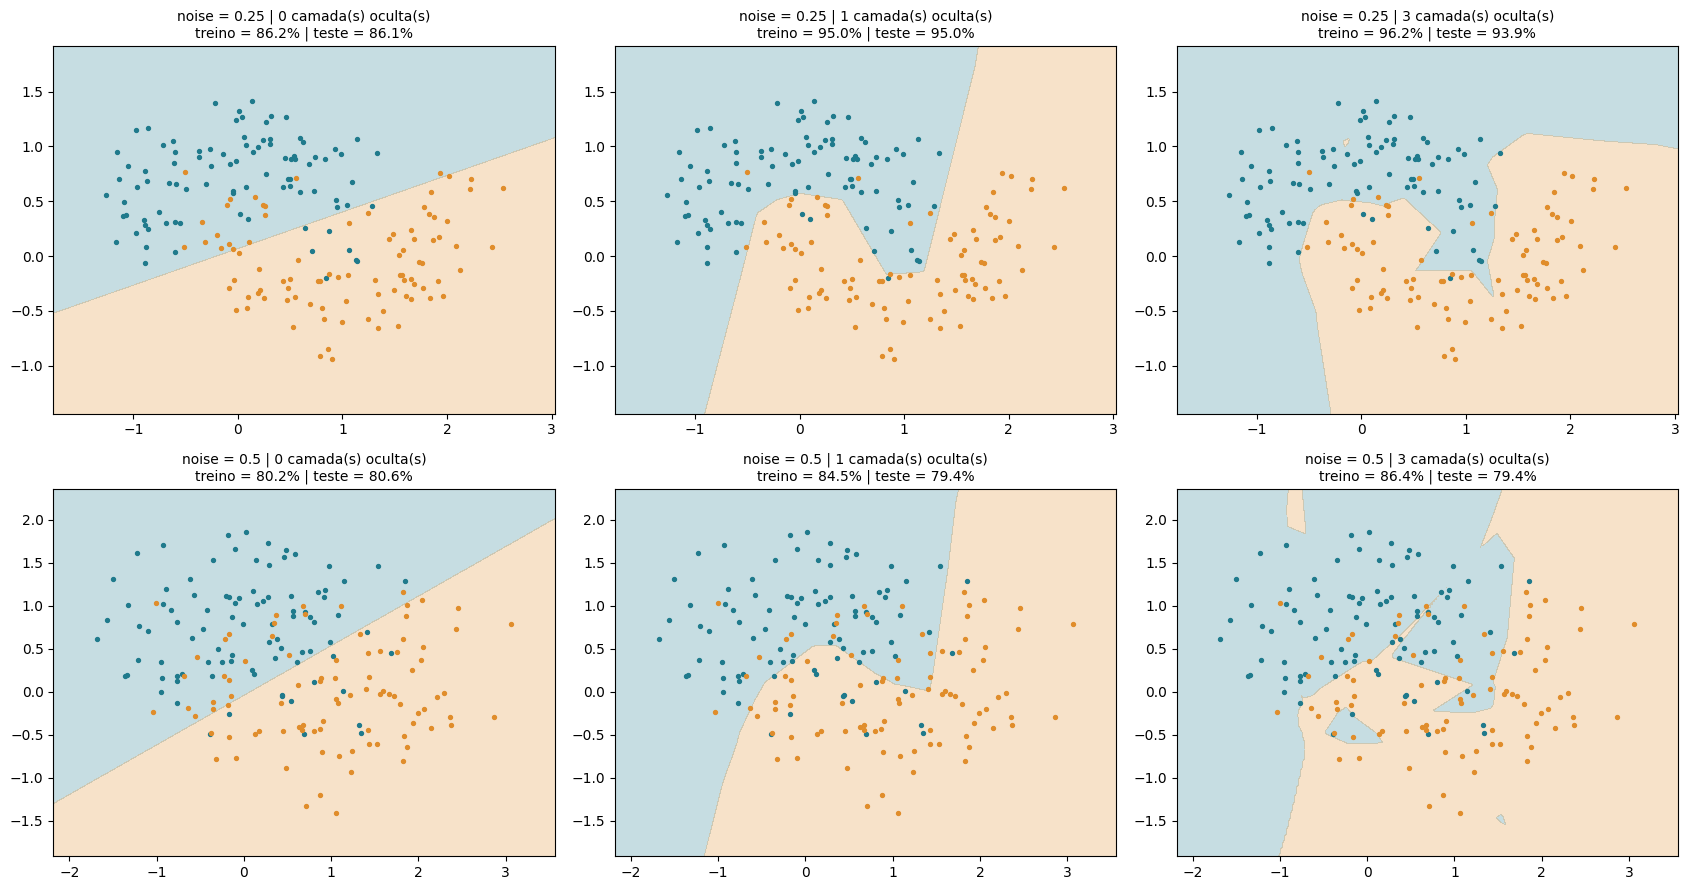

 noise | camadas | acc treino | acc teste
  0.25 |       0 |      86.2% |     86.1%
  0.25 |       1 |      95.0% |     95.0%
  0.25 |       3 |      96.2% |     93.9%
   0.5 |       0 |      80.2% |     80.6%
   0.5 |       1 |      84.5% |     79.4%
   0.5 |       3 |      86.4% |     79.4%


In [24]:
fig, eixos = plt.subplots(2, 3, figsize=(17, 9))
tabela_ex1 = []

for linha, ruido in enumerate([0.25, 0.5]):
    (X_tr_, X_te_, y_tr_, y_te_), (Xtr, Ytr, Xte, Yte) = dados[ruido]
    for coluna, n in enumerate([0, 1, 3]):
        torch.manual_seed(42)
        modelo = criar_rede(n)
        treinar_luas(modelo, Xtr, Ytr)
        acc_tr, acc_te = acuracia(modelo, Xtr, Ytr), acuracia(modelo, Xte, Yte)
        tabela_ex1.append((ruido, n, acc_tr, acc_te))
        fronteira(eixos[linha, coluna], modelo, X_te_, y_te_,
                  f"noise = {ruido} | {n} camada(s) oculta(s)\ntreino = {acc_tr:.1%} | teste = {acc_te:.1%}")

plt.tight_layout(); plt.show()

print(f"{'noise':>6} | {'camadas':>7} | {'acc treino':>10} | {'acc teste':>9}")
for ruido, n, acc_tr, acc_te in tabela_ex1:
    print(f"{ruido:>6} | {n:>7} | {acc_tr:>10.1%} | {acc_te:>9.1%}")

**Quanto dá para acertar no máximo?** Com ruído alto, alguns pontos de uma classe caem bem no meio da outra. Nenhum modelo consegue acertá-los. Para estimar esse teto, gero um conjunto **muito grande** (20 mil pontos de treino e 20 mil de teste) com o mesmo ruído. Com tantos dados, a rede aprende uma fronteira próxima da ideal, e sua acurácia no teste aproxima a melhor acurácia possível.

In [25]:
def teto_acuracia(ruido, n=40000):
    X, y = make_moons(n_samples=n, noise=ruido, random_state=0)
    Xg = torch.tensor(X, dtype=torch.float32); Yg = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    meio = n // 2
    torch.manual_seed(0)
    modelo = criar_rede(3)
    treinar_luas(modelo, Xg[:meio], Yg[:meio], epocas=1000)
    return acuracia(modelo, Xg[meio:], Yg[meio:])

for ruido in [0.25, 0.5]:
    print(f"noise = {ruido}: acurácia máxima estimada ≈ {teto_acuracia(ruido):.1%}")

noise = 0.25: acurácia máxima estimada ≈ 94.5%


noise = 0.5: acurácia máxima estimada ≈ 82.6%


Por fim, os 180 pontos de teste são poucos, então a acurácia de um único sorteio dos dados varia bastante. Repito a comparação com 10 sorteios diferentes de `make_moons`, usando a rede de 1 camada oculta.

In [26]:
res_ruido = {0.25: [], 0.5: []}
for semente in range(10):
    for ruido in res_ruido:
        _, (Xtr, Ytr, Xte, Yte) = gerar_luas(ruido, semente=semente)
        torch.manual_seed(42)
        modelo = criar_rede(1)
        treinar_luas(modelo, Xtr, Ytr)
        res_ruido[ruido].append(acuracia(modelo, Xte, Yte))

for ruido, accs in res_ruido.items():
    accs = np.array(accs)
    print(f"noise = {ruido}: acurácia no teste média = {accs.mean():.1%} | mín = {accs.min():.1%} | máx = {accs.max():.1%}")

noise = 0.25: acurácia no teste média = 93.7% | mín = 91.7% | máx = 96.7%
noise = 0.5: acurácia no teste média = 80.3% | mín = 76.7% | máx = 85.0%


**Interpretação — Exercício 1**

**Sim, a acurácia cai bastante.** A rede com 1 camada oculta passou de 95,0% para 79,4% no teste. A de 3 camadas caiu de 93,9% para 79,4%. Na média dos 10 sorteios de dados, a queda foi de 93,7% para 80,3%.

**Por quê?** O problema ficou mais difícil, não a rede que ficou pior.

- **As classes passam a se misturar.** Com `noise=0.5`, muitos pontos azuis caem dentro da região das laranjas e vice-versa, como se vê nos gráficos. Um ponto azul no meio de vários laranjas é indistinguível deles: qualquer fronteira razoável vai errá-lo.
- **Existe um teto de acurácia, e ele baixou.** Com 20 mil pontos, estimei a melhor acurácia possível em cerca de 94,5% para `noise=0.25` e cerca de 82,6% para `noise=0.5`. As redes ficam perto desse teto nos dois casos. Ou seja, a perda de acurácia vem quase toda da **sobreposição entre as classes**, e não de uma falha do modelo. Nenhuma rede, por maior que seja, acertaria muito mais que 82% com esse nível de ruído.
- **A vantagem das camadas ocultas quase some.** Com pouco ruído, a fronteira curva ganha da reta por quase 9 pontos percentuais. Com muito ruído, a reta (80,6%) fica até um pouco acima das redes com camadas ocultas (79,4%). O formato de "lua" fica escondido pelo ruído, e a curvatura extra deixa de compensar.
- **O sobreajuste aumenta.** Com `noise=0.5`, a diferença entre treino e teste cresce: 84,5% contra 79,4% na rede de 1 camada, e 86,4% contra 79,4% na de 3. A fronteira da rede de 3 camadas forma "ilhas" e "pontas" para abraçar pontos isolados do treino. Ela está decorando o ruído, e isso não ajuda nos dados novos.

**Observação sobre os números.** A rede de 1 camada com `noise=0.25` teve 95,0% no teste, um pouco acima do teto estimado de 94,5%. Isso não é contradição. O teste tem só 180 pontos, então cada ponto vale cerca de 0,6 ponto percentual, e um sorteio "fácil" pode passar do teto. Por isso também olhei a média de 10 sorteios, que ficou abaixo do teto, como esperado.

---
### Funções auxiliares para os exercícios 2, 3 e 4

As três perguntas seguintes envolvem treinar redes no MNIST várias vezes. Para não repetir código, crio:

- `criar_mlp`: monta a rede com as camadas ocultas que eu pedir;
- `acuracia_mnist`: percorre um `DataLoader` e devolve a fração de acertos;
- `treinar_mnist`: treina por várias épocas e guarda a acurácia no treino e no teste **ao final de cada época**. Assim, um único treino de 5 épocas também me diz como a rede estava na época 3.

A semente controla os pesos iniciais **e** a ordem dos lotes, através do `generator` do `DataLoader`.

In [27]:
import time

def criar_mlp(ocultas):
    camadas = [nn.Flatten()]
    entrada = 784
    for n in ocultas:
        camadas += [nn.Linear(entrada, n), nn.ReLU()]
        entrada = n
    camadas.append(nn.Linear(entrada, 10))
    return nn.Sequential(*camadas)


def acuracia_mnist(modelo, carregador):
    acertos, total = 0, 0
    with torch.no_grad():
        for imagens, rotulos in carregador:
            acertos += (modelo(imagens).argmax(dim=1) == rotulos).sum().item()
            total += len(rotulos)
    return acertos / total


def treinar_mnist(ocultas, conj_treino, conj_teste, epocas=5, semente=0, lr=0.001):
    torch.manual_seed(semente)
    modelo = criar_mlp(ocultas)
    carregador = DataLoader(conj_treino, batch_size=64, shuffle=True,
                            generator=torch.Generator().manual_seed(semente))
    aval_treino = DataLoader(conj_treino, batch_size=1000)
    aval_teste = DataLoader(conj_teste, batch_size=1000)

    perda_fn = nn.CrossEntropyLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"treino": [], "teste": []}
    for epoca in range(epocas):
        for imagens, rotulos in carregador:
            perda = perda_fn(modelo(imagens), rotulos)
            otimizador.zero_grad()
            perda.backward()
            otimizador.step()
        hist["treino"].append(acuracia_mnist(modelo, aval_treino))
        hist["teste"].append(acuracia_mnist(modelo, aval_teste))
    return modelo, hist


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

---
### Exercício 2 — 5 épocas em vez de 3

> Na Parte 2, treine a rede por 5 épocas em vez de 3. A acurácia no teste melhora?

Treino a mesma arquitetura da aula (`784 → 128 → 64 → 10`) por 5 épocas, com três sementes. Como guardo a acurácia ao final de cada época, comparo diretamente a época 3 com a época 5 **do mesmo treino**.

In [28]:
SEMENTES = [0, 1, 2]
EPOCAS = 5

inicio = time.time()
hist_2camadas = {}
for s in SEMENTES:
    _, hist_2camadas[s] = treinar_mnist([128, 64], mnist_treino, mnist_teste, epocas=EPOCAS, semente=s)
    print(f"semente {s}: teste por época = " + "  ".join(f"{a:.2%}" for a in hist_2camadas[s]["teste"]))
print(f"\ntempo: {time.time() - inicio:.0f} s")

semente 0: teste por época = 95.16%  96.83%  97.16%  97.35%  97.13%


semente 1: teste por época = 94.30%  96.55%  97.04%  97.10%  97.31%


semente 2: teste por época = 94.27%  96.21%  96.86%  97.36%  97.57%

tempo: 70 s


época 3: teste = 97.02% (± 0.12%) | treino = 97.79% | diferença treino - teste = 0.77%
época 5: teste = 97.34% (± 0.18%) | treino = 98.59% | diferença treino - teste = 1.25%

ganho no teste da época 3 para a 5, por semente: -0.03%  +0.27%  +0.71%


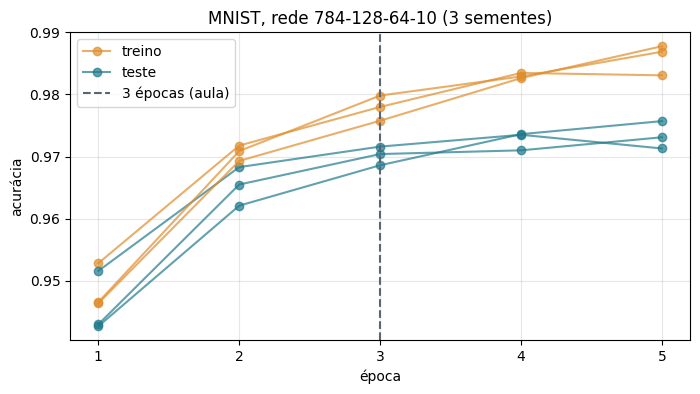

In [29]:
def resumo(historicos, epoca, conjunto="teste"):
    return np.array([h[conjunto][epoca - 1] for h in historicos.values()])

for ep in [3, 5]:
    te, tr = resumo(hist_2camadas, ep, "teste"), resumo(hist_2camadas, ep, "treino")
    print(f"época {ep}: teste = {te.mean():.2%} (± {te.std():.2%}) | treino = {tr.mean():.2%} | diferença treino - teste = {tr.mean() - te.mean():.2%}")

ganho = resumo(hist_2camadas, 5) - resumo(hist_2camadas, 3)
print("\nganho no teste da época 3 para a 5, por semente:", "  ".join(f"{g:+.2%}" for g in ganho))

epocas = np.arange(1, EPOCAS + 1)
fig, eixo = plt.subplots(figsize=(8, 4))
for s, h in hist_2camadas.items():
    eixo.plot(epocas, h["treino"], color=LARANJA, marker="o", alpha=0.7, label="treino" if s == 0 else None)
    eixo.plot(epocas, h["teste"], color=AZUL, marker="o", alpha=0.7, label="teste" if s == 0 else None)
eixo.axvline(3, color=CINZA, linestyle="--", label="3 épocas (aula)")
eixo.set_xlabel("época"); eixo.set_ylabel("acurácia"); eixo.set_xticks(epocas)
eixo.set_title("MNIST, rede 784-128-64-10 (3 sementes)"); eixo.legend(); eixo.grid(alpha=0.3)
plt.show()

**Interpretação — Exercício 2**

**Melhora, mas pouco.** Na média das três sementes, a acurácia no teste passou de 97,02% na época 3 para 97,34% na época 5: um ganho de cerca de 0,3 ponto percentual. Isso equivale a uns 30 acertos a mais em 10 mil imagens.

- **O ganho não é garantido.** Por semente, o ganho foi de −0,03, +0,27 e +0,71 pontos percentuais. Na semente 0, a acurácia chegou a cair da época 4 para a 5. Com diferenças desse tamanho, a escolha da semente pesa quase tanto quanto as duas épocas extras.
- **Os ganhos diminuem a cada época.** Da época 1 para a 2, o teste sobe cerca de 2 pontos. Da 2 para a 3, cerca de 0,6. Da 3 para a 5, só 0,3 no total. A rede já aprendeu quase tudo o que consegue nas primeiras épocas.
- **O treino sobe mais rápido que o teste.** A diferença entre treino e teste passou de 0,8 para 1,3 ponto percentual. A rede continua melhorando nas imagens que já viu, mas esse ganho se transfere cada vez menos para imagens novas. É o começo do sobreajuste. Com muitas épocas a mais, a acurácia no teste provavelmente pararia de subir ou até começaria a cair.

**Conclusão:** treinar 5 épocas dá um ganho pequeno e incerto. Para saber quando parar, o ideal é acompanhar a acurácia em dados que a rede não usa para treinar, como fiz aqui, época a época.

---
### Exercício 3 — Removendo a segunda camada oculta

> Ainda na Parte 2, remova a segunda camada oculta (deixe `nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)`). A acurácia muda muito?

In [30]:
rede_1camada = criar_mlp([128])
print(rede_1camada)
print("\nparâmetros com 1 camada oculta  :", contar_parametros(rede_1camada))
print("parâmetros com 2 camadas ocultas:", contar_parametros(criar_mlp([128, 64])))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)

parâmetros com 1 camada oculta  : 101770
parâmetros com 2 camadas ocultas: 109386


A diferença de parâmetros é pequena: quase todos estão na primeira camada, que liga os 784 pixels aos 128 neurônios ($784 \times 128 = 100\,352$ pesos). Treino a rede de uma camada com as mesmas sementes e o mesmo número de épocas do Exercício 2.

In [31]:
inicio = time.time()
hist_1camada = {}
for s in SEMENTES:
    _, hist_1camada[s] = treinar_mnist([128], mnist_treino, mnist_teste, epocas=EPOCAS, semente=s)
    print(f"semente {s}: teste por época = " + "  ".join(f"{a:.2%}" for a in hist_1camada[s]["teste"]))
print(f"\ntempo: {time.time() - inicio:.0f} s\n")

for ep in [3, 5]:
    um, dois = resumo(hist_1camada, ep), resumo(hist_2camadas, ep)
    print(f"época {ep}: 1 camada = {um.mean():.2%} (± {um.std():.2%}) | 2 camadas = {dois.mean():.2%} (± {dois.std():.2%}) "
          f"| diferença = {dois.mean() - um.mean():+.2%}")

semente 0: teste por época = 94.64%  96.20%  96.80%  97.34%  97.39%


semente 1: teste por época = 94.22%  96.01%  97.00%  97.10%  97.50%


semente 2: teste por época = 94.33%  96.17%  96.88%  97.26%  97.33%

tempo: 68 s

época 3: 1 camada = 96.89% (± 0.08%) | 2 camadas = 97.02% (± 0.12%) | diferença = +0.13%
época 5: 1 camada = 97.41% (± 0.07%) | 2 camadas = 97.34% (± 0.18%) | diferença = -0.07%


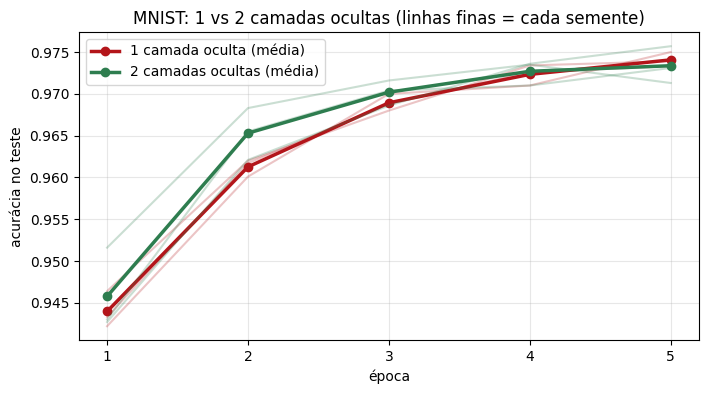

In [32]:
fig, eixo = plt.subplots(figsize=(8, 4))
for nome, hists, cor in [("1 camada oculta", hist_1camada, VERMELHO), ("2 camadas ocultas", hist_2camadas, VERDE)]:
    media = np.mean([h["teste"] for h in hists.values()], axis=0)
    for h in hists.values():
        eixo.plot(epocas, h["teste"], color=cor, alpha=0.25)
    eixo.plot(epocas, media, color=cor, marker="o", linewidth=2.5, label=f"{nome} (média)")
eixo.set_xlabel("época"); eixo.set_ylabel("acurácia no teste"); eixo.set_xticks(epocas)
eixo.set_title("MNIST: 1 vs 2 camadas ocultas (linhas finas = cada semente)"); eixo.legend(); eixo.grid(alpha=0.3)
plt.show()

**Interpretação — Exercício 3**

**Não, a acurácia praticamente não muda.**

- Na época 3, a rede de 1 camada teve 96,89% contra 97,02% da rede de 2 camadas: uma diferença de 0,13 ponto percentual.
- Na época 5, a ordem até se inverteu: 97,41% para 1 camada contra 97,34% para 2 camadas.
- Essas diferenças são do mesmo tamanho da variação entre sementes. No gráfico, as linhas finas das duas arquiteturas se cruzam o tempo todo. Não dá para dizer que uma é melhor que a outra.

**Por que a segunda camada faz tão pouca diferença?**

- **Quase todos os parâmetros estão na primeira camada.** Ela liga 784 pixels a 128 neurônios, o que dá mais de 100 mil pesos. A segunda camada só acrescenta uns 8 mil. Remover a segunda camada tira apenas 7% dos parâmetros.
- **Uma camada oculta já basta para este problema.** Com 128 neurônios, a rede rasa já separa bem os dígitos. Profundidade extra só ajuda quando o problema precisa de representações mais elaboradas.
- **O limite está em outro lugar.** As duas redes começam com `nn.Flatten()`, que transforma a imagem em uma fila de números e joga fora a informação de quais pixels são vizinhos. Para passar de cerca de 97,5%, faz mais diferença usar uma arquitetura que aproveite essa estrutura espacial, como as redes convolucionais da aula 08, do que empilhar mais camadas `Linear`.

Este resultado combina com a Parte 1: mais camadas nem sempre significam mais acurácia.

---
### Exercício 4 — FashionMNIST

> Troque `datasets.MNIST` por `datasets.FashionMNIST` (imagens de roupas e calçados, mesmo formato). A rede acerta mais ou menos?

O FashionMNIST foi criado justamente como um substituto mais difícil do MNIST. Ele tem o mesmo formato: 60 mil imagens de treino, 10 mil de teste, $28 \times 28$ pixels em tons de cinza e 10 classes. Por isso, nada no código da rede precisa mudar.

imagens de treino: 60000 | imagens de teste: 10000
formato de uma imagem: torch.Size([1, 28, 28])


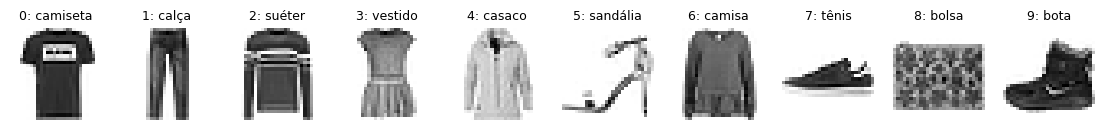

In [33]:
fashion_treino = datasets.FashionMNIST(root="dados", train=True,  download=True, transform=transforms.ToTensor())
fashion_teste  = datasets.FashionMNIST(root="dados", train=False, download=True, transform=transforms.ToTensor())

NOMES = ["camiseta", "calça", "suéter", "vestido", "casaco", "sandália", "camisa", "tênis", "bolsa", "bota"]
print("imagens de treino:", len(fashion_treino), "| imagens de teste:", len(fashion_teste))
print("formato de uma imagem:", fashion_treino[0][0].shape)

plt.figure(figsize=(14, 3))
for c in range(10):
    i = (fashion_treino.targets == c).nonzero()[0].item()
    plt.subplot(1, 10, c + 1)
    plt.imshow(fashion_treino[i][0][0], cmap="gray_r")
    plt.title(f"{c}: {NOMES[c]}", fontsize=9); plt.axis("off")
plt.show()

Treino exatamente a mesma rede da aula (`784 → 128 → 64 → 10`), com as mesmas sementes e 5 épocas.

semente 0: teste por época = 84.42%  85.19%  85.17%  86.74%  87.26%


semente 1: teste por época = 84.27%  85.15%  86.56%  86.55%  86.63%


semente 2: teste por época = 84.17%  85.33%  86.36%  86.77%  87.60%

tempo: 70 s

época 3: MNIST = 97.02% | FashionMNIST = 86.03% (treino 87.73%) | erros a cada 100 imagens: 3.0 vs 14.0
época 5: MNIST = 97.34% | FashionMNIST = 87.16% (treino 89.22%) | erros a cada 100 imagens: 2.7 vs 12.8


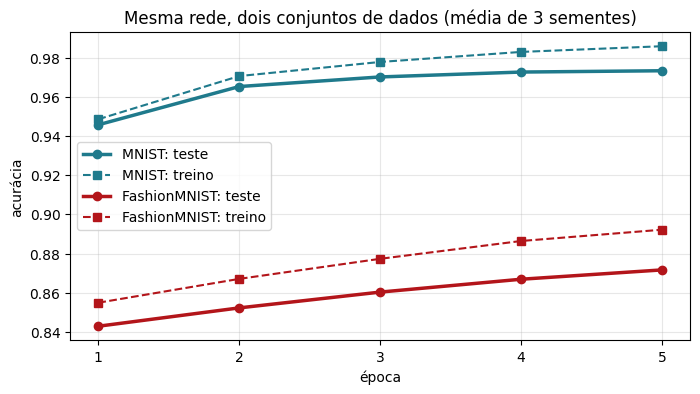

In [34]:
inicio = time.time()
hist_fashion, modelos_fashion = {}, {}
for s in SEMENTES:
    modelos_fashion[s], hist_fashion[s] = treinar_mnist([128, 64], fashion_treino, fashion_teste, epocas=EPOCAS, semente=s)
    print(f"semente {s}: teste por época = " + "  ".join(f"{a:.2%}" for a in hist_fashion[s]["teste"]))
print(f"\ntempo: {time.time() - inicio:.0f} s\n")

for ep in [3, 5]:
    m, f = resumo(hist_2camadas, ep), resumo(hist_fashion, ep)
    ftr = resumo(hist_fashion, ep, "treino")
    print(f"época {ep}: MNIST = {m.mean():.2%} | FashionMNIST = {f.mean():.2%} (treino {ftr.mean():.2%}) "
          f"| erros a cada 100 imagens: {100 * (1 - m.mean()):.1f} vs {100 * (1 - f.mean()):.1f}")

fig, eixo = plt.subplots(figsize=(8, 4))
for nome, hists, cor in [("MNIST", hist_2camadas, AZUL), ("FashionMNIST", hist_fashion, VERMELHO)]:
    eixo.plot(epocas, np.mean([h["teste"] for h in hists.values()], axis=0), color=cor, marker="o", linewidth=2.5, label=f"{nome}: teste")
    eixo.plot(epocas, np.mean([h["treino"] for h in hists.values()], axis=0), color=cor, marker="s", linestyle="--", label=f"{nome}: treino")
eixo.set_xlabel("época"); eixo.set_ylabel("acurácia"); eixo.set_xticks(epocas)
eixo.set_title("Mesma rede, dois conjuntos de dados (média de 3 sementes)"); eixo.legend(); eixo.grid(alpha=0.3)
plt.show()

Para entender **onde** a rede erra, calculo a acurácia por classe e a **matriz de confusão**. Na matriz, a linha é a classe verdadeira e a coluna é a classe prevista. Os números fora da diagonal são os erros: por exemplo, a célula na linha "camisa" e coluna "camiseta" conta quantas camisas a rede chamou de camiseta.

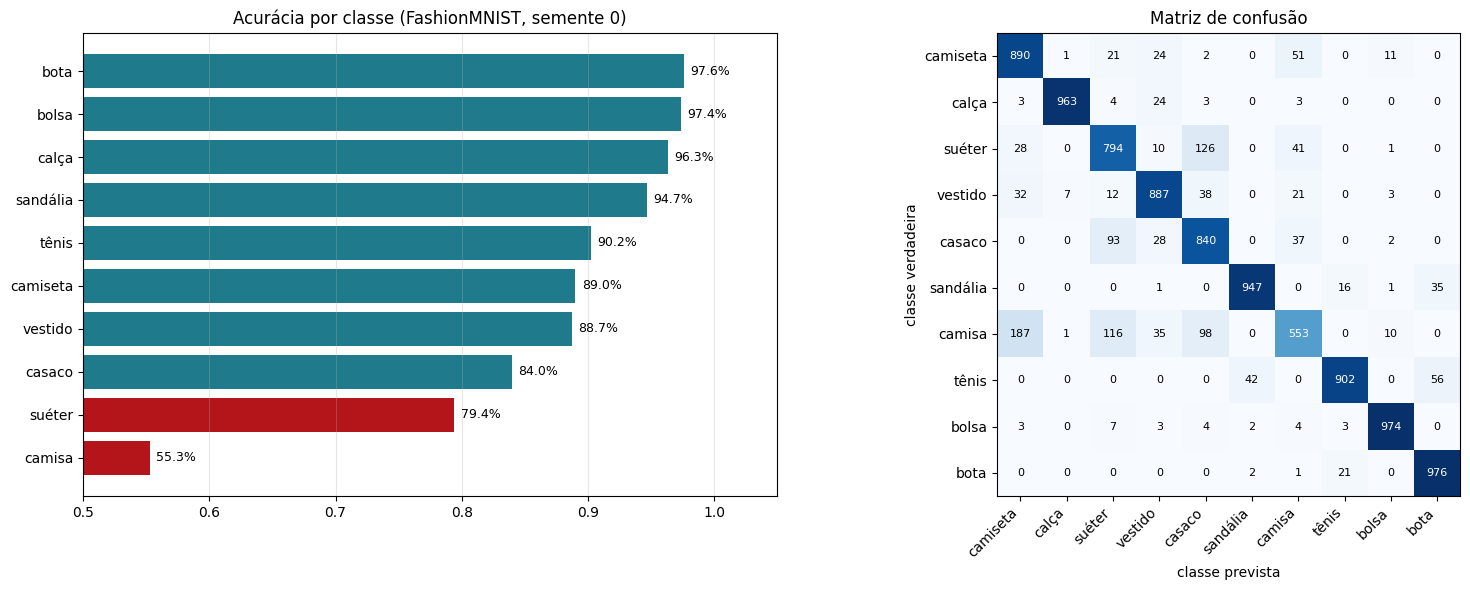

confusões mais frequentes (verdadeira -> prevista):
     camisa -> camiseta : 187 imagens
     suéter -> casaco   : 126 imagens
     camisa -> suéter   : 116 imagens
     camisa -> casaco   : 98 imagens
     casaco -> suéter   : 93 imagens


In [35]:
from sklearn.metrics import confusion_matrix

modelo_f = modelos_fashion[0]
with torch.no_grad():
    imgs_f = torch.stack([fashion_teste[i][0] for i in range(len(fashion_teste))])
    prev_f = modelo_f(imgs_f).argmax(dim=1).numpy()
real_f = fashion_teste.targets.numpy()

mc = confusion_matrix(real_f, prev_f)
acc_classe = mc.diagonal() / mc.sum(axis=1)

fig, eixos = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.3]})
ordem = np.argsort(acc_classe)
eixos[0].barh([NOMES[i] for i in ordem], acc_classe[ordem], color=[VERMELHO if acc_classe[i] < 0.8 else AZUL for i in ordem])
for k, i in enumerate(ordem):
    eixos[0].text(acc_classe[i] + 0.005, k, f"{acc_classe[i]:.1%}", va="center", fontsize=9)
eixos[0].set_xlim(0.5, 1.05); eixos[0].set_title("Acurácia por classe (FashionMNIST, semente 0)"); eixos[0].grid(alpha=0.3, axis="x")

im = eixos[1].imshow(mc, cmap="Blues")
eixos[1].set_xticks(range(10)); eixos[1].set_xticklabels(NOMES, rotation=45, ha="right")
eixos[1].set_yticks(range(10)); eixos[1].set_yticklabels(NOMES)
for i in range(10):
    for j in range(10):
        eixos[1].text(j, i, mc[i, j], ha="center", va="center", fontsize=8, color="white" if mc[i, j] > mc.max() / 2 else "black")
eixos[1].set_xlabel("classe prevista"); eixos[1].set_ylabel("classe verdadeira"); eixos[1].set_title("Matriz de confusão")
plt.tight_layout(); plt.show()

fora = mc.copy(); np.fill_diagonal(fora, 0)
print("confusões mais frequentes (verdadeira -> prevista):")
for k in np.argsort(fora.ravel())[::-1][:5]:
    i, j = divmod(k, 10)
    print(f"  {NOMES[i]:>9s} -> {NOMES[j]:<9s}: {fora[i, j]} imagens")

Alguns exemplos de erro, para ver se fazem sentido:

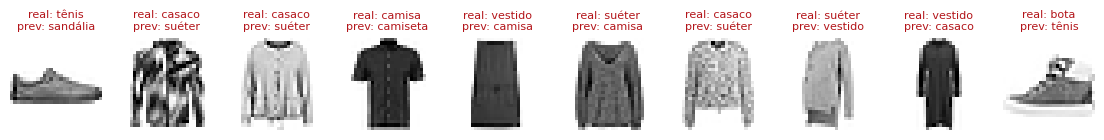

In [36]:
erros_f = np.nonzero(prev_f != real_f)[0]
plt.figure(figsize=(14, 3.2))
for k, i in enumerate(erros_f[:10]):
    plt.subplot(1, 10, k + 1)
    plt.imshow(imgs_f[i][0], cmap="gray_r")
    plt.title(f"real: {NOMES[real_f[i]]}\nprev: {NOMES[prev_f[i]]}", color=VERMELHO, fontsize=8)
    plt.axis("off")
plt.show()

**Interpretação — Exercício 4**

**A rede acerta bem menos.** Com a mesma arquitetura, as mesmas sementes e o mesmo treino, a acurácia no teste cai de 97,0% no MNIST para 86,0% no FashionMNIST, após 3 épocas. Em outras palavras, a rede passa de cerca de 3 para cerca de 14 erros a cada 100 imagens: quase cinco vezes mais. Com 5 épocas, chega a 87,2%.

**Por que é mais difícil?**

- **Várias classes são muito parecidas.** A matriz de confusão mostra que os erros se concentram em peças de cima do corpo: camisa, camiseta, suéter e casaco. Numa imagem de $28 \times 28$ em tons de cinza, todas são um retângulo com mangas. A **camisa** é a pior classe, com só 55% de acerto, e é confundida com camiseta, suéter e casaco. A confusão mais comum é camisa sendo chamada de camiseta.
- **Os calçados se confundem entre si, mas não com roupas.** Tênis, sandália e bota trocam de lugar algumas vezes, mas quase nunca são chamados de camisa ou de calça. A rede aprendeu bem a separar os grandes grupos e erra dentro de cada grupo.
- **Classes com formato próprio vão muito bem.** Calça, bolsa e bota passam de 96%, quase no nível do MNIST. Elas têm silhuetas únicas.
- **Dentro de uma mesma classe há muita variação.** No MNIST, um dígito é definido pelo traçado, e duas pessoas escrevem um "3" de forma parecida. No FashionMNIST, um casaco pode ser liso, listrado, claro ou escuro. Estampas e texturas mudam muito os pixels sem mudar a classe.
- **Muitos erros são compreensíveis.** Nos exemplos, um casaco claro aberto parece um suéter, e um vestido escuro e reto parece um casaco. Algumas dessas imagens seriam difíceis até para uma pessoa.

**O que isso indica?** A acurácia no treino também fica baixa, cerca de 89%. Logo, o problema principal não é sobreajuste, e sim falta de capacidade: a rede não consegue nem separar bem as imagens que já viu. Mais épocas ajudam um pouco. O ganho maior viria de uma arquitetura que enxergue formas e texturas locais, como as redes convolucionais.

Esse exercício também mostra por que o FashionMNIST foi criado: o MNIST ficou fácil demais, e qualquer rede simples passa de 97%. Um conjunto mais difícil diferencia melhor os modelos.

---
### Conclusões gerais

1. **A acurácia depende tanto dos dados quanto do modelo.** Com muito ruído nas luas, as classes se misturam e há um teto de acurácia que nenhuma rede ultrapassa.
2. **Mais épocas trazem ganhos cada vez menores.** No MNIST, passar de 3 para 5 épocas rendeu só cerca de 0,3 ponto percentual, enquanto a diferença entre treino e teste começou a crescer.
3. **Mais camadas nem sempre ajudam.** Tirar a segunda camada oculta não mudou a acurácia no MNIST. Na Parte 1, a rede de 3 camadas também não superou a de 1.
4. **A mesma rede pode ir bem em um problema e mal em outro.** A arquitetura que acerta 97% dos dígitos acerta só cerca de 87% das roupas, porque as classes do FashionMNIST são mais parecidas entre si.
5. **Comparações justas exigem cuidado.** Fixar sementes e repetir os experimentos foi essencial: várias diferenças que pareciam relevantes em um único treino eram menores que a variação entre sementes.